Implemented image augmentation, compare reasonable augmentation settings using model validation performance, and export the best-scoring candidate for the training teammate.

This notebook uses the team's updated `split.csv` (columns `path`, `class`, `split`). It preserves the supplied split. It **does not use the test set for tuning**.

### Augmentations
Flips, rotation, zoom in/out, brightness including darkening, contrast/saturation/hue jitter, mild blur, sensor noise, cutout (maximum 20%), and optional synthetic background variation. Background variation uses a heuristic GrabCut foreground mask; review the saved mask examples before relying on it.

### How the tuning works
A pretrained ResNet-50 backbone is frozen; only a new 38-class linear head is trained. Candidate transforms are compared on a stratified subset of the **training** split and evaluated on the full **validation** split. The notebook ranks configurations by validation macro-F1 (accuracy is a secondary metric), writes the best augmented configuration, and compares it with a no-augmentation baseline. This is a manageable screening experiment, not a claim that one configuration is universally optimal.

### Inputs to attach
1. PlantVillage dataset with the original `color` images.
2. The team's updated `split.csv` with `path`, `class`, and `split` columns.

## 1. Setup

In [1]:
from pathlib import Path
import math
import random
import json
import zipfile
import shutil
import inspect
from typing import Optional, Union

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torchvision
from torch import nn
from torch.utils.data import Dataset, DataLoader, TensorDataset
from PIL import Image
from torchvision import transforms as T
from torchvision.transforms import InterpolationMode

SEED = 42
IMG_SIZE = 224
MAX_CUTOUT_AREA = 0.20
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)
BACKGROUND_PALETTE = [
    (166, 166, 158), (196, 181, 153), (151, 169, 178),
    (157, 169, 147), (210, 204, 188), (151, 139, 125),
]
INPUT_ROOT = Path("/kaggle/input")
COLOR_DIR = Path("/kaggle/input/datasets/abdallahalidev/plantvillage-dataset/color")
OUTPUT_DIR = Path("/kaggle/working/augmentation_handoff_pytorch")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("PyTorch:", torch.__version__)
print("torchvision:", torchvision.__version__)
print("OpenCV (used only for foreground masking):", cv2.__version__)
print("Colour image folder exists:", COLOR_DIR.is_dir())
print("Outputs:", OUTPUT_DIR)

PyTorch: 2.11.0+cu128
torchvision: 0.26.0+cu128
OpenCV (used only for foreground masking): 4.14.0
Colour image folder exists: True
Outputs: /kaggle/working/augmentation_handoff_pytorch


## 2. Load the updated split CSV

This input has three columns: `path` (relative image path), `class` (label), and `split` (`train`, `val`, or `test`). We prioritise a file named `split.csv`, so the updated split is used instead of an older manifest.

In [2]:
# Kaggle's current mounted layout is /kaggle/input/datasets/<owner>/<dataset>/split.csv.
# These are shallow path checks; they do not scan the image tree.
split_candidates = sorted(set(
    list(INPUT_ROOT.glob("datasets/*/*/split.csv"))
    + list(INPUT_ROOT.glob("*/*/split.csv"))
))

if len(split_candidates) == 0:
    raise FileNotFoundError(
        "Could not find split.csv. Use Add Input to attach the updated split dataset."
    )
if len(split_candidates) > 1:
    print("Found multiple split.csv files:")
    for candidate in split_candidates:
        print(" -", candidate)
    raise RuntimeError("Keep only the intended updated split.csv attached, then rerun this cell.")

SPLIT_CSV = split_candidates[0]
splits_df = pd.read_csv(SPLIT_CSV)
required_columns = {"path", "class", "split"}
if not required_columns.issubset(splits_df.columns):
    raise ValueError(f"split.csv must contain {required_columns}. Found: {splits_df.columns.tolist()}")

print("Using split:", SPLIT_CSV)
print("Rows:", f"{len(splits_df):,}")
print("Classes:", splits_df["class"].nunique())
display(splits_df.head())

Using split: /kaggle/input/datasets/astitvasrivastava05/split-aug/split.csv
Rows: 53,705
Classes: 38


,path,class,split
0,Soybean___healthy/85478cac-7aed-4797-982b-410a...,Soybean___healthy,train
1,Tomato___Tomato_Yellow_Leaf_Curl_Virus/1a867f1...,Tomato___Tomato_Yellow_Leaf_Curl_Virus,train
2,Tomato___Leaf_Mold/30f6aead-5cd9-453d-85e6-56e...,Tomato___Leaf_Mold,train
3,Apple___healthy/9decdcd8-8027-4901-8da6-bd27c0...,Apple___healthy,train
4,Peach___Bacterial_spot/b269e00a-55a1-4e18-bab5...,Peach___Bacterial_spot,train


## 3. Match CSV paths to original colour images

The new CSV uses `path` and `class`, unlike the old notebook. Paths such as `Tomato___Leaf_Mold/example.JPG` are relative to the `color` directory.

In [3]:
# Standardise path separators and remove accidental leading slashes.
splits_df["image_relpath"] = (
    splits_df["path"].astype(str).str.replace("\\", "/", regex=False).str.strip().str.lstrip("/")
)

# Directly resolve paths from the manifest; no full directory crawl is needed.
splits_df["resolved_image_path"] = splits_df["image_relpath"].map(
    lambda relpath: str(COLOR_DIR / relpath)
)

exists_mask = splits_df["resolved_image_path"].map(lambda value: Path(value).is_file())
missing = splits_df.loc[~exists_mask, ["path", "class"]]
print(f"Image paths found: {int(exists_mask.sum()):,} / {len(splits_df):,}")
print("Missing paths:", len(missing))

if len(missing):
    display(missing.head(10))
    raise FileNotFoundError("Some image paths were not found. Verify the split.csv and PlantVillage inputs.")

folder_labels = splits_df["image_relpath"].str.split("/").str[0]
mismatch_count = int((folder_labels != splits_df["class"]).sum())
print("Label/folder mismatches:", mismatch_count)
if mismatch_count:
    display(splits_df.loc[folder_labels != splits_df["class"], ["path", "class"]].head(10))
    raise ValueError("Some class labels disagree with their image-folder names.")

Image paths found: 53,705 / 53,705
Missing paths: 0
Label/folder mismatches: 0


## 4. Validate the existing split

This section checks the team's split; it does **not** shuffle or reassign images.

In [4]:
splits_df["split"] = (
    splits_df["split"].astype(str).str.strip().str.lower()
    .replace({"validation": "val", "valid": "val"})
)
allowed_splits = {"train", "val", "test"}
unknown_splits = sorted(set(splits_df["split"]) - allowed_splits)
if unknown_splits:
    raise ValueError(f"Unexpected split values: {unknown_splits}")

if splits_df["image_relpath"].duplicated().any():
    duplicates = splits_df[splits_df["image_relpath"].duplicated(keep=False)]
    display(duplicates.head(10))
    raise ValueError("Duplicate paths found in split.csv. Ask the duplicate-cleaning teammate to review.")

split_summary = splits_df["split"].value_counts().reindex(["train", "val", "test"], fill_value=0)
print("Images by split:")
print(split_summary.to_string())
print("Unique images:", f"{splits_df['image_relpath'].nunique():,}")
print("Classes:", splits_df["class"].nunique())
class_split_counts = pd.crosstab(splits_df["class"], splits_df["split"]).reindex(
    columns=["train", "val", "test"], fill_value=0
)
print("Classes missing from a split:", int((class_split_counts == 0).any(axis=1).sum()))

train_df = splits_df[splits_df["split"] == "train"].reset_index(drop=True)
val_df = splits_df[splits_df["split"] == "val"].reset_index(drop=True)
test_df = splits_df[splits_df["split"] == "test"].reset_index(drop=True)

Images by split:
split
train    37751
val       7976
test      7978
Unique images: 53,705
Classes: 38
Classes missing from a split: 0


## 5. Image-loading helper

PyTorch transforms work with PIL images or tensors. We load each source file as an RGB PIL image here; the transform later resizes it and converts it to a PyTorch tensor.

In [5]:
def load_rgb_image(path: Union[str, "Path"]) -> Image.Image:
    """Open an image and return a detached RGB PIL image."""
    with Image.open(path) as image:
        return image.convert("RGB").copy()

## 6. Background variation: estimate the leaf mask

To vary the background without intentionally changing the leaf, we first estimate which pixels belong to the foreground. This uses OpenCV's GrabCut segmentation algorithm, with a central foreground seed and a thin background border.

**Important limitation:** this is a heuristic mask, not a hand-annotated leaf segmentation dataset. A poor mask could remove part of a leaf or lesion. The notebook will display the mask and several replacement examples so they can be inspected before training.

In [6]:
def get_foreground_alpha(image: Image.Image) -> Optional[np.ndarray]:
    """Estimate the foreground/leaf mask as a float alpha image in [0, 1].

    GrabCut uses a central foreground seed and a thin sure-background border.
    Returns None if the estimated mask is implausibly small/large or GrabCut fails.
    Visually inspect the mask on several classes before relying on background replacement.
    """
    rgb = np.asarray(image.convert("RGB"))
    height, width = rgb.shape[:2]
    if height < 24 or width < 24:
        return None

    bgr = cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR)
    mask = np.full((height, width), cv2.GC_PR_FGD, dtype=np.uint8)

    # Mark only a thin border as definite background so leaves near the edge are less likely to be cut off.
    border = max(1, round(min(height, width) * 0.015))
    mask[:border, :] = cv2.GC_BGD
    mask[-border:, :] = cv2.GC_BGD
    mask[:, :border] = cv2.GC_BGD
    mask[:, -border:] = cv2.GC_BGD

    # Seed the central region as definite foreground; GrabCut refines its boundary.
    center = (width // 2, height // 2)
    axes = (max(5, int(width * 0.15)), max(5, int(height * 0.22)))
    cv2.ellipse(mask, center, axes, 0, 0, 360, cv2.GC_FGD, thickness=-1)

    background_model = np.zeros((1, 65), dtype=np.float64)
    foreground_model = np.zeros((1, 65), dtype=np.float64)
    try:
        cv2.grabCut(
            bgr, mask, None, background_model, foreground_model,
            iterCount=3, mode=cv2.GC_INIT_WITH_MASK,
        )
    except cv2.error:
        return None

    foreground = np.isin(mask, (cv2.GC_FGD, cv2.GC_PR_FGD)).astype(np.uint8)
    foreground_fraction = float(foreground.mean())
    if not 0.08 <= foreground_fraction <= 0.92:
        return None

    # Close tiny holes and softly feather the edge to reduce a hard composite seam.
    kernel = np.ones((3, 3), dtype=np.uint8)
    foreground = cv2.morphologyEx(foreground, cv2.MORPH_CLOSE, kernel, iterations=1)
    alpha = cv2.GaussianBlur(foreground.astype(np.float32), (0, 0), sigmaX=1.2)
    return np.clip(alpha, 0.0, 1.0)

## 7. Create varied backgrounds and composite the leaf

The background generator supports three styles: muted solid colour, a soft gradient, and low-frequency texture. A soft alpha edge helps avoid a hard cutout seam. If the foreground mask looks implausible, the function returns the original image unchanged.

In [7]:
def _make_background(height: int, width: int, mode: str = "random") -> np.ndarray:
    """Create a muted solid, gradient or softly textured synthetic RGB background."""
    allowed = {"random", "solid", "gradient", "texture"}
    if mode not in allowed:
        raise ValueError(f"mode must be one of {sorted(allowed)}")
    if mode == "random":
        mode = random.choice(["solid", "gradient", "texture"])

    palette = np.asarray(BACKGROUND_PALETTE, dtype=np.float32)
    if mode == "solid":
        colour = palette[random.randrange(len(palette))]
        background = np.empty((height, width, 3), dtype=np.float32)
        background[:] = colour
        # Small low-amplitude variation avoids a perfectly artificial flat colour.
        background += np.random.normal(0, 1.5, size=(height, width, 1)).astype(np.float32)

    elif mode == "gradient":
        colour_a = palette[random.randrange(len(palette))]
        colour_b = palette[random.randrange(len(palette))]
        if random.choice([True, False]):
            blend = np.linspace(0.0, 1.0, height, dtype=np.float32)[:, None, None]
            background = colour_a[None, None, :] * (1 - blend) + colour_b[None, None, :] * blend
            background = np.broadcast_to(background, (height, width, 3)).copy()
        else:
            blend = np.linspace(0.0, 1.0, width, dtype=np.float32)[None, :, None]
            background = colour_a[None, None, :] * (1 - blend) + colour_b[None, None, :] * blend
            background = np.broadcast_to(background, (height, width, 3)).copy()
        background += np.random.normal(0, 2.0, size=(height, width, 1)).astype(np.float32)

    else:  # texture
        base = palette[random.randrange(len(palette))]
        small_h, small_w = max(4, height // 18), max(4, width // 18)
        low_res = np.random.normal(
            loc=base, scale=12.0, size=(small_h, small_w, 3)
        ).astype(np.float32)
        background = cv2.resize(low_res, (width, height), interpolation=cv2.INTER_CUBIC)
        background = cv2.GaussianBlur(background, (0, 0), sigmaX=3.0)

    return np.clip(background, 0, 255).astype(np.uint8)


def replace_background(
    image: Image.Image,
    mode: str = "random",
    alpha: Optional[np.ndarray] = None,
    return_mask: bool = False,
):
    """Replace the estimated background; keep the estimated foreground as-is.

    If segmentation is uncertain, the original image is returned unchanged.
    When return_mask=True, returns (image, alpha); alpha is None if segmentation failed.
    """
    image = image.convert("RGB")
    rgb = np.asarray(image)
    if alpha is None:
        alpha = get_foreground_alpha(image)
    if alpha is None:
        return (image.copy(), None) if return_mask else image.copy()

    background = _make_background(rgb.shape[0], rgb.shape[1], mode=mode)
    alpha_3d = alpha[:, :, None]
    composite = rgb.astype(np.float32) * alpha_3d + background.astype(np.float32) * (1.0 - alpha_3d)
    result = Image.fromarray(np.clip(composite, 0, 255).astype(np.uint8), mode="RGB")
    return (result, alpha) if return_mask else result


class RandomBackgroundVariation:
    """Torchvision-compatible PIL transform that substitutes a background."""
    def __call__(self, image: Image.Image) -> Image.Image:
        return replace_background(image, mode="random")

## 8. Sensor noise and cutout helpers

These transforms operate on PyTorch tensors shaped `[channels, height, width]`. Noise is mild and cutout is capped at 20% of total image area.

In [8]:
def sample_cutout_box(
    height: int,
    width: int,
    min_area: float = 0.02,
    max_area: float = MAX_CUTOUT_AREA,
) -> tuple[int, int, int, int]:
    """Return (top, left, cut_h, cut_w) whose pixel area is <= max_area."""
    if not 0.0 < min_area <= max_area <= 0.20:
        raise ValueError("Require 0 < min_area <= max_area <= 0.20")
    target_area = random.uniform(min_area, max_area) * height * width
    aspect = random.uniform(0.5, 2.0)  # width / height
    cut_h = max(1, min(height, int(math.floor(math.sqrt(target_area / aspect)))))
    cut_w = max(1, min(width, int(math.floor(math.sqrt(target_area * aspect)))))
    top = random.randint(0, height - cut_h)
    left = random.randint(0, width - cut_w)
    return top, left, cut_h, cut_w


class RandomGaussianNoise:
    """Add mild Gaussian sensor noise to a [C,H,W] torch tensor in [0,1]."""
    def __init__(self, probability: float = 0.20, std: float = 0.02):
        self.probability = probability
        self.std = std

    def __call__(self, tensor: torch.Tensor) -> torch.Tensor:
        if random.random() >= self.probability:
            return tensor
        noise = torch.randn_like(tensor) * self.std
        return (tensor + noise).clamp(0.0, 1.0)


class RandomCutout:
    """Hide one random rectangle; its area never exceeds max_area of the image."""
    def __init__(
        self,
        probability: float = 0.25,
        max_area: float = MAX_CUTOUT_AREA,
        min_area: float = 0.02,
    ):
        if not 0.0 < min_area <= max_area <= 0.20:
            raise ValueError("Require 0 < min_area <= max_area <= 0.20")
        self.probability = probability
        self.max_area = max_area
        self.min_area = min_area

    def __call__(self, tensor: torch.Tensor) -> torch.Tensor:
        if random.random() >= self.probability:
            return tensor
        if tensor.ndim != 3:
            raise ValueError("RandomCutout expects a [C,H,W] image tensor")

        _, height, width = tensor.shape
        top, left, cut_h, cut_w = sample_cutout_box(
            height, width, min_area=self.min_area, max_area=self.max_area
        )
        output = tensor.clone()
        fill = output.mean(dim=(1, 2), keepdim=True)
        output[:, top:top + cut_h, left:left + cut_w] = fill
        return output

## 9. Build training and evaluation transforms

**Zoom:** `RandomAffine(scale=...)` performs zoom in/out: scales above 1 zoom in and below 1 zoom out. Normal mode uses scale 0.85–1.15 and rotation ±30°; strong mode uses scale 0.75–1.25 and rotation ±40°. `RandomAffine` is a torchvision transform with explicit ranges for both rotation and scale. [Official torchvision documentation](https://docs.pytorch.org/vision/stable/generated/torchvision.transforms.RandomAffine.html).

**Background:** replacement is applied probabilistically (20% by default) to training images only. Since segmentation can occasionally be imperfect, examine the background preview before using this setting for a full training run.

`build_eval_transform()` only resizes and converts to a tensor. It does not augment validation or test images.

In [9]:
def build_train_transform(
    image_size: int = IMG_SIZE,
    strong: bool = False,
    background_probability: float = 0.20,
    cutout_max_area: float = MAX_CUTOUT_AREA,
    zoom_scale: Optional[tuple[float, float]] = None,
    normalize: bool = False,
    rotation_degrees: Optional[float] = None,
    brightness_range: Optional[tuple[float, float]] = None,
    contrast_range: Optional[tuple[float, float]] = None,
    saturation_range: Optional[tuple[float, float]] = None,
    hue_strength: Optional[float] = None,
    blur_probability: Optional[float] = None,
    blur_sigma: tuple[float, float] = (0.5, 1.2),
    noise_probability: Optional[float] = None,
    noise_std: Optional[float] = None,
    cutout_probability: Optional[float] = None,
) -> T.Compose:
    """Build a configurable PyTorch augmentation transform. Training images only.

    Exposed knobs make the settings testable as hyperparameters:
    - rotation_degrees and zoom_scale control geometric strength
    - brightness/contrast/saturation/hue control colour jitter
    - blur_probability, noise_probability/std control image imperfections
    - cutout_probability and cutout_max_area control occlusion
    - background_probability controls synthetic background replacement
    Set normalize=True when using ImageNet-pretrained ResNet-50 features.
    """
    if rotation_degrees is None:
        rotation_degrees = 40 if strong else 30
    if zoom_scale is None:
        zoom_scale = (0.75, 1.25) if strong else (0.85, 1.15)
    if brightness_range is None:
        brightness_range = (0.60, 1.40)
    if contrast_range is None:
        contrast_range = (0.75, 1.25) if strong else (0.80, 1.20)
    if saturation_range is None:
        saturation_range = (0.75, 1.25) if strong else (0.80, 1.20)
    if hue_strength is None:
        hue_strength = 0.03 if strong else 0.02
    if blur_probability is None:
        blur_probability = 0.30 if strong else 0.20
    if noise_probability is None:
        noise_probability = 0.30 if strong else 0.20
    if noise_std is None:
        noise_std = 0.03 if strong else 0.02
    if cutout_probability is None:
        cutout_probability = 0.35 if strong else 0.25

    if not 0.0 <= background_probability <= 1.0:
        raise ValueError("background_probability must be in [0, 1]")
    if not 0.0 < cutout_max_area <= MAX_CUTOUT_AREA:
        raise ValueError("cutout_max_area must be greater than 0 and at most 0.20")
    if not 0.0 < zoom_scale[0] <= zoom_scale[1]:
        raise ValueError("zoom_scale must be an increasing pair of positive values")
    if not 0.0 <= blur_probability <= 1.0:
        raise ValueError("blur_probability must be in [0, 1]")
    if not 0.0 <= noise_probability <= 1.0:
        raise ValueError("noise_probability must be in [0, 1]")
    if not 0.0 <= cutout_probability <= 1.0:
        raise ValueError("cutout_probability must be in [0, 1]")
    if not 0.0 <= hue_strength <= 0.5:
        raise ValueError("hue_strength must be in [0, 0.5]")

    steps = [
        T.Resize((image_size, image_size), interpolation=InterpolationMode.BILINEAR),
        T.RandomHorizontalFlip(p=0.5),
        T.RandomVerticalFlip(p=0.5),
        T.RandomAffine(
            degrees=(-rotation_degrees, rotation_degrees),
            translate=(0.02, 0.02),
            scale=zoom_scale,
            interpolation=InterpolationMode.BILINEAR,
            fill=(127, 127, 127),
        ),
    ]

    if background_probability > 0:
        steps.append(T.RandomApply([RandomBackgroundVariation()], p=background_probability))

    steps.extend([
        T.ColorJitter(
            brightness=brightness_range,
            contrast=contrast_range,
            saturation=saturation_range,
            hue=hue_strength,
        ),
        T.RandomApply([
            T.GaussianBlur(kernel_size=3, sigma=blur_sigma)
        ], p=blur_probability),
        T.ToTensor(),
        RandomGaussianNoise(probability=noise_probability, std=noise_std),
        RandomCutout(probability=cutout_probability, max_area=cutout_max_area),
    ])

    if normalize:
        steps.append(T.Normalize(IMAGENET_MEAN, IMAGENET_STD))

    return T.Compose(steps)


def build_eval_transform(
    image_size: int = IMG_SIZE,
    normalize: bool = False,
) -> T.Compose:
    """Deterministic resize/tensor conversion for validation and test; no augmentation."""
    steps = [
        T.Resize((image_size, image_size), interpolation=InterpolationMode.BILINEAR),
        T.ToTensor(),
    ]
    if normalize:
        steps.append(T.Normalize(IMAGENET_MEAN, IMAGENET_STD))
    return T.Compose(steps)

## 10. Smoke test: one training image

Class: Tomato___Tomato_Yellow_Leaf_Curl_Virus
Split: train
Augmented tensor shape [C,H,W]: (3, 224, 224)
Augmented tensor range: 0.0 to 0.5137255191802979
Eval tensor shape: (3, 224, 224)
PyTorch transform smoke test passed.


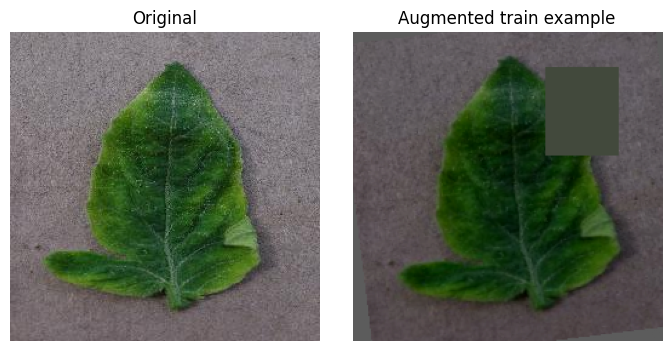

In [10]:
example_row = train_df.sample(1, random_state=SEED).iloc[0]
original_pil = load_rgb_image(example_row["resolved_image_path"])
train_transform = build_train_transform(background_probability=0.0, normalize=False)  # keep background replacement off until its mask is approved
eval_transform = build_eval_transform(normalize=False)
augmented_tensor = train_transform(original_pil)
validation_tensor = eval_transform(original_pil)

print("Class:", example_row["class"])
print("Split:", example_row["split"])
print("Augmented tensor shape [C,H,W]:", tuple(augmented_tensor.shape))
print("Augmented tensor range:", float(augmented_tensor.min()), "to", float(augmented_tensor.max()))
print("Eval tensor shape:", tuple(validation_tensor.shape))
assert tuple(augmented_tensor.shape) == (3, IMG_SIZE, IMG_SIZE)
assert 0.0 <= float(augmented_tensor.min()) and float(augmented_tensor.max()) <= 1.0
print("PyTorch transform smoke test passed.")

fig, axes = plt.subplots(1, 2, figsize=(7, 3.5))
axes[0].imshow(np.asarray(original_pil)); axes[0].set_title("Original"); axes[0].axis("off")
axes[1].imshow(augmented_tensor.permute(1, 2, 0).cpu().numpy()); axes[1].set_title("Augmented train example"); axes[1].axis("off")
plt.tight_layout(); plt.show()

## 11. Preview the background mask before using it

The mask preview is important: white represents the estimated leaf/foreground and black represents the estimated background. Check that the complete leaf and its disease lesions remain in the white area.

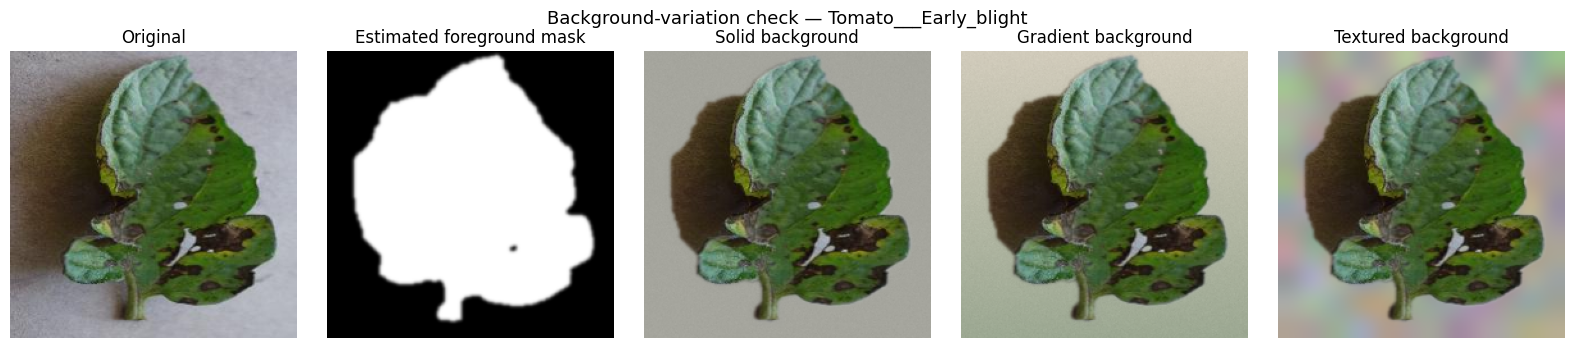

Foreground-mask fraction: 51.8%
Saved: /kaggle/working/augmentation_handoff_pytorch/background_variation_showcase.png


In [11]:
background_example = None
background_alpha = None
candidates = train_df.sample(min(20, len(train_df)), random_state=SEED + 5)

for _, row in candidates.iterrows():
    candidate_image = load_rgb_image(row["resolved_image_path"]).resize((IMG_SIZE, IMG_SIZE))
    candidate_alpha = get_foreground_alpha(candidate_image)
    if candidate_alpha is not None:
        background_example = candidate_image
        background_alpha = candidate_alpha
        background_label = row["class"]
        break

if background_example is None:
    print("No usable GrabCut mask was found in 20 sampled training images. Background replacement will safely fall back to the original image for those cases; inspect segmentation before increasing its use.")
else:
    background_variants = [
        replace_background(background_example, mode="solid", alpha=background_alpha),
        replace_background(background_example, mode="gradient", alpha=background_alpha),
        replace_background(background_example, mode="texture", alpha=background_alpha),
    ]
    fig, axes = plt.subplots(1, 5, figsize=(16, 3.5))
    axes[0].imshow(background_example); axes[0].set_title("Original"); axes[0].axis("off")
    axes[1].imshow(background_alpha, cmap="gray", vmin=0, vmax=1); axes[1].set_title("Estimated foreground mask"); axes[1].axis("off")
    for ax, variant, title in zip(axes[2:], background_variants, ["Solid background", "Gradient background", "Textured background"]):
        ax.imshow(variant); ax.set_title(title); ax.axis("off")
    fig.suptitle(f"Background-variation check — {background_label}", fontsize=13)
    plt.tight_layout()
    BACKGROUND_GRID_PATH = OUTPUT_DIR / "background_variation_showcase.png"
    fig.savefig(BACKGROUND_GRID_PATH, dpi=180, bbox_inches="tight")
    plt.show()
    print("Foreground-mask fraction:", f"{float((background_alpha > 0.5).mean()):.1%}")
    print("Saved:", BACKGROUND_GRID_PATH)

## 12. Before/after grid

**Display note:** PIL source images are converted from uint8 `[0, 255]` to float `[0, 1]` before plotting, so original images display with the same pixel scale as augmented tensors.


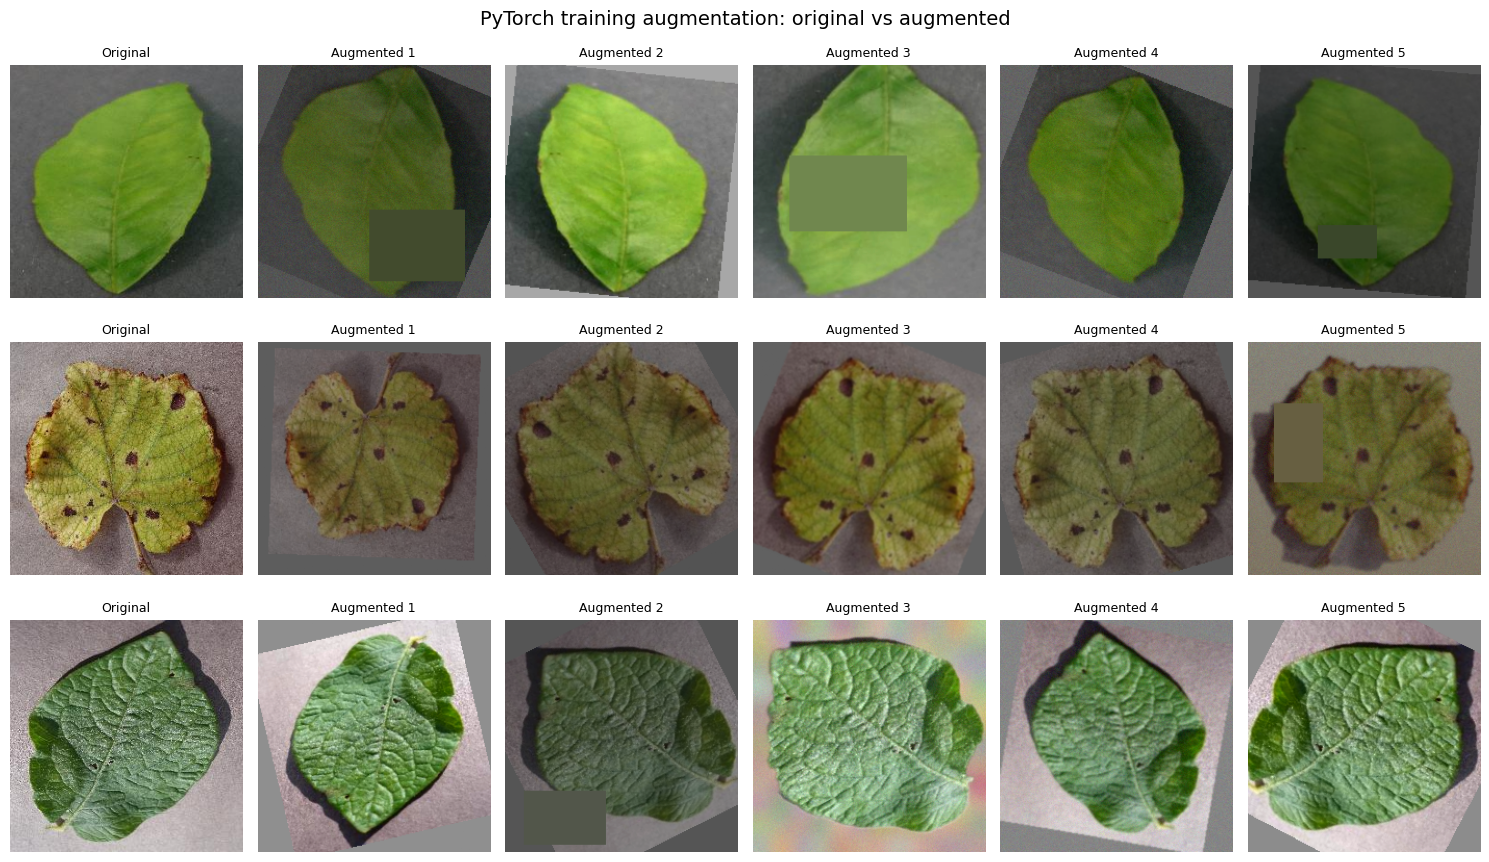

Saved: /kaggle/working/augmentation_handoff_pytorch/augmentation_before_after_grid.png


In [12]:
class_counts = train_df["class"].value_counts().sort_values(ascending=False)
ordered_labels = class_counts.index.tolist()
chosen_labels = list(dict.fromkeys([
    ordered_labels[0],
    ordered_labels[len(ordered_labels) // 2],
    ordered_labels[-1],
]))

fig, axes = plt.subplots(len(chosen_labels), 6, figsize=(15, 3.0 * len(chosen_labels)))
axes = np.asarray(axes).reshape(len(chosen_labels), 6)

for row_index, label in enumerate(chosen_labels):
    sample_row = train_df[train_df["class"] == label].sample(1, random_state=SEED + row_index).iloc[0]
    original = load_rgb_image(sample_row["resolved_image_path"])
    images = [original] + [build_train_transform(background_probability=0.20)(original) for _ in range(5)]
    # PIL originals are uint8 [0, 255]; convert them to float RGB [0, 1] before plotting.
    original_array = np.asarray(original.convert("RGB"), dtype=np.float32)
    if original_array.max() > 1.0:
        original_array /= 255.0

    display_images = [original_array] + [
        tensor.permute(1, 2, 0).detach().cpu().numpy().astype(np.float32)
        for tensor in images[1:]
    ]
    titles = ["Original"] + [f"Augmented {i}" for i in range(1, 6)]
    for ax, image_array, title in zip(axes[row_index], display_images, titles):
        ax.imshow(np.clip(image_array, 0, 1)); ax.set_title(title, fontsize=9); ax.axis("off")
    axes[row_index, 0].set_ylabel(label, rotation=0, labelpad=80, va="center", fontsize=8)

fig.suptitle("PyTorch training augmentation: original vs augmented", fontsize=14)
plt.tight_layout()
GRID_PATH = OUTPUT_DIR / "augmentation_before_after_grid.png"
fig.savefig(GRID_PATH, dpi=180, bbox_inches="tight")
plt.show()
print("Saved:", GRID_PATH)

## 13. Individual effects, including zoom

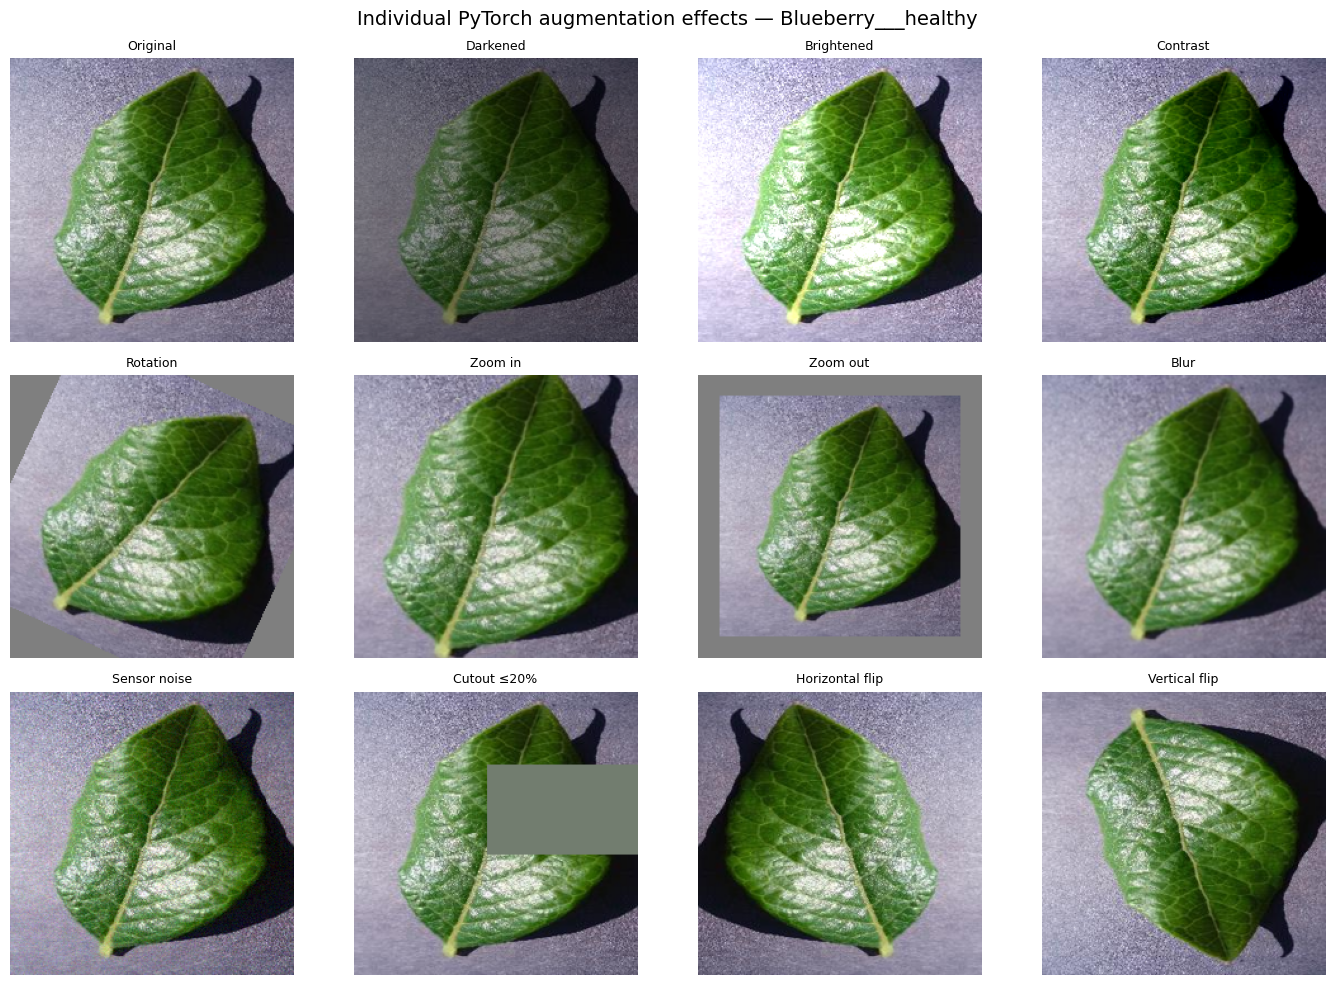

Saved: /kaggle/working/augmentation_handoff_pytorch/augmentation_effects_showcase.png


In [13]:
from torchvision.transforms import functional as TF

show_row = train_df.sample(1, random_state=SEED + 10).iloc[0]
base_image = load_rgb_image(show_row["resolved_image_path"]).resize((IMG_SIZE, IMG_SIZE))
noise_tensor = RandomGaussianNoise(probability=1.0, std=0.03)(T.ToTensor()(base_image))
cutout_tensor = RandomCutout(probability=1.0, max_area=MAX_CUTOUT_AREA)(T.ToTensor()(base_image))

effect_images = [
    base_image,
    TF.adjust_brightness(base_image, 0.60),
    TF.adjust_brightness(base_image, 1.35),
    TF.adjust_contrast(base_image, 1.20),
    TF.affine(base_image, angle=25, translate=[0, 0], scale=1.0, shear=[0.0, 0.0], interpolation=InterpolationMode.BILINEAR, fill=(127,127,127)),
    TF.affine(base_image, angle=0, translate=[0, 0], scale=1.15, shear=[0.0, 0.0], interpolation=InterpolationMode.BILINEAR, fill=(127,127,127)),
    TF.affine(base_image, angle=0, translate=[0, 0], scale=0.85, shear=[0.0, 0.0], interpolation=InterpolationMode.BILINEAR, fill=(127,127,127)),
    T.GaussianBlur(kernel_size=3, sigma=0.9)(base_image),
    T.ToPILImage()(noise_tensor),
    T.ToPILImage()(cutout_tensor),
    TF.hflip(base_image),
    TF.vflip(base_image),
]
effect_titles = ["Original", "Darkened", "Brightened", "Contrast", "Rotation", "Zoom in", "Zoom out", "Blur", "Sensor noise", "Cutout ≤20%", "Horizontal flip", "Vertical flip"]

fig, axes = plt.subplots(3, 4, figsize=(14, 10))
for ax, image, title in zip(axes.ravel(), effect_images, effect_titles):
    ax.imshow(np.asarray(image)); ax.set_title(title, fontsize=9); ax.axis("off")
fig.suptitle(f"Individual PyTorch augmentation effects — {show_row['class']}", fontsize=14)
plt.tight_layout()
EFFECTS_PATH = OUTPUT_DIR / "augmentation_effects_showcase.png"
fig.savefig(EFFECTS_PATH, dpi=180, bbox_inches="tight")
plt.show()
print("Saved:", EFFECTS_PATH)

## 14. Verify the cutout limit

In [14]:
cutout_areas = []
for _ in range(1000):
    _, _, cut_h, cut_w = sample_cutout_box(IMG_SIZE, IMG_SIZE, max_area=MAX_CUTOUT_AREA)
    cutout_areas.append((cut_h * cut_w) / (IMG_SIZE * IMG_SIZE))

largest_area = max(cutout_areas)
print(f"Largest sampled cutout: {largest_area:.2%}")
print(f"Configured maximum: {MAX_CUTOUT_AREA:.2%}")
assert largest_area <= MAX_CUTOUT_AREA + 1e-9
print("Cutout limit test passed.")

Largest sampled cutout: 19.88%
Configured maximum: 20.00%
Cutout limit test passed.


## 15. Tune augmentation settings using a frozen ResNet-50

This experiment compares a no-augmentation baseline with up to five augmentation configurations. Two background-related candidates are included only after the foreground-mask preview has been approved. To keep the Kaggle run manageable, it uses up to **50 training images per class** (stratified by class) but evaluates each configuration on the **entire validation split**.

The ResNet-50 backbone is frozen; only a newly initialized 38-class linear head is trained for each configuration. Macro-F1 is the primary selection metric because it gives each class equal weight. Accuracy is reported as a secondary metric.

**The test split is not loaded or evaluated in this experiment.** Because only a subset of training images is used for the screening run, treat the winning config as the best candidate among those tested, then let the model-training teammate retrain on the full training split.

### 15A. Prepare a fair, stratified tuning sample

The same sample of training rows is used for every candidate. The validation rows are not augmented.

In [15]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Tuning device:", DEVICE)
if DEVICE.type != "cuda":
    raise RuntimeError(
        "Enable a GPU in Kaggle: Settings -> Accelerator -> GPU, then rerun this section. "
        "Extracting ResNet-50 features for this validation sweep on CPU can be very slow."
    )

TUNE_TRAIN_PER_CLASS = 50
FEATURE_BATCH_SIZE = 32
HEAD_BATCH_SIZE = 256
HEAD_EPOCHS = 8
NUM_WORKERS = 2

class_names = sorted(splits_df["class"].unique().tolist())
class_to_idx = {name: idx for idx, name in enumerate(class_names)}

# Fixed, stratified subset: choose up to 50 training images per class.
train_sample_parts = []
for class_name, group in train_df.groupby("class", sort=True):
    train_sample_parts.append(
        group.sample(n=min(TUNE_TRAIN_PER_CLASS, len(group)), random_state=SEED)
    )
tune_train_df = pd.concat(train_sample_parts).sample(frac=1, random_state=SEED).reset_index(drop=True)
tune_val_df = val_df.copy().reset_index(drop=True)  # full validation set, unaugmented

print("Training images used per class: up to", TUNE_TRAIN_PER_CLASS)
print("Tuning training subset:", f"{len(tune_train_df):,}")
print("Full validation images:", f"{len(tune_val_df):,}")
print("Class count:", len(class_names))
print("Test rows will not be used in this experiment.")

Tuning device: cuda
Training images used per class: up to 50
Tuning training subset: 1,900
Full validation images: 7,976
Class count: 38
Test rows will not be used in this experiment.


### 15B. Define the image dataset and frozen ResNet-50

PyTorch's `Dataset` loads one image and its class ID. ResNet-50 converts each image into a 2,048-number feature vector. The backbone's weights are frozen; a small linear classifier learns the 38 class labels from these vectors.

In [16]:
class ManifestImageDataset(Dataset):
    def __init__(self, frame, transform, label_map):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform
        self.label_map = label_map

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        image = load_rgb_image(row["resolved_image_path"])
        tensor = self.transform(image)
        label_id = self.label_map[row["class"]]
        return tensor, label_id


# Pretrained ImageNet weights; torchvision may download them the first time.
weights = torchvision.models.ResNet50_Weights.DEFAULT
backbone = torchvision.models.resnet50(weights=weights)
backbone.fc = nn.Identity()  # return 2,048 features instead of ImageNet's 1,000 logits
for parameter in backbone.parameters():
    parameter.requires_grad = False
backbone = backbone.to(DEVICE).eval()

print("Frozen ResNet-50 feature extractor ready.")
print("Backbone parameters trainable:", sum(p.requires_grad for p in backbone.parameters()))
print("New classifier outputs:", len(class_names))

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 163MB/s] 


Frozen ResNet-50 feature extractor ready.
Backbone parameters trainable: 0
New classifier outputs: 38


### 15C. Extract reusable image features

The validation features are computed once because validation uses deterministic, unaugmented images. Each candidate gets its own training features, generated using that candidate's transform.

In [17]:
@torch.inference_mode()
def extract_features(frame, transform, description):
    dataset = ManifestImageDataset(frame, transform, class_to_idx)
    loader = DataLoader(
        dataset,
        batch_size=FEATURE_BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=True,
    )
    feature_batches = []
    label_batches = []
    total_batches = len(loader)

    for batch_number, (images, labels) in enumerate(loader, start=1):
        images = images.to(DEVICE, non_blocking=True)
        features = backbone(images)
        feature_batches.append(features.cpu())
        label_batches.append(labels.cpu())

        if batch_number == 1 or batch_number % 20 == 0 or batch_number == total_batches:
            print(f"{description}: batch {batch_number}/{total_batches}")

    return torch.cat(feature_batches), torch.cat(label_batches)


eval_transform_for_model = build_eval_transform(normalize=True)
val_features, val_labels = extract_features(
    tune_val_df, eval_transform_for_model, "Unaugmented validation"
)
print("Validation feature matrix:", tuple(val_features.shape))
print("Validation labels:", tuple(val_labels.shape))

Unaugmented validation: batch 1/250
Unaugmented validation: batch 20/250
Unaugmented validation: batch 40/250
Unaugmented validation: batch 60/250
Unaugmented validation: batch 80/250
Unaugmented validation: batch 100/250
Unaugmented validation: batch 120/250
Unaugmented validation: batch 140/250
Unaugmented validation: batch 160/250
Unaugmented validation: batch 180/250
Unaugmented validation: batch 200/250
Unaugmented validation: batch 220/250
Unaugmented validation: batch 240/250
Unaugmented validation: batch 250/250
Validation feature matrix: (7976, 2048)
Validation labels: (7976,)


### 15D. Choose the hyperparameter configurations to compare

The baseline disables augmentation. The other candidates compare cutout caps of 10%, 15%, and 20%, the effect of adding a 10% probability of background variation, and a wider zoom/rotation setting. The rest of the settings are written explicitly so the experiment is reproducible.

**Background safety:** inspect the foreground-mask and background-variation preview in Section 11 before tuning. If the full leaf and lesions are inside the foreground mask, set `BACKGROUND_MASKS_APPROVED = True` in the next code cell and rerun from there. Otherwise leave it `False`; background candidates will be skipped.

In [18]:
BASE_AUGMENT_PARAMS = {
    "rotation_degrees": 30,
    "zoom_scale": (0.85, 1.15),
    "brightness_range": (0.60, 1.40),
    "contrast_range": (0.80, 1.20),
    "saturation_range": (0.80, 1.20),
    "hue_strength": 0.02,
    "blur_probability": 0.20,
    "blur_sigma": (0.5, 1.2),
    "noise_probability": 0.20,
    "noise_std": 0.02,
    "cutout_probability": 0.25,
}

TUNING_CONFIGS = [
    {
        "name": "no_augmentation_baseline",
        "augmentation": False,
        "transform_kwargs": {},
    },
    {
        "name": "cutout_10_zoom_moderate_bg_0",
        "augmentation": True,
        "transform_kwargs": {**BASE_AUGMENT_PARAMS, "cutout_max_area": 0.10, "background_probability": 0.0},
    },
    {
        "name": "cutout_15_zoom_moderate_bg_0",
        "augmentation": True,
        "transform_kwargs": {**BASE_AUGMENT_PARAMS, "cutout_max_area": 0.15, "background_probability": 0.0},
    },
    {
        "name": "cutout_20_zoom_moderate_bg_0",
        "augmentation": True,
        "transform_kwargs": {**BASE_AUGMENT_PARAMS, "cutout_max_area": 0.20, "background_probability": 0.0},
    },
    {
        "name": "cutout_15_background_10pct",
        "augmentation": True,
        "transform_kwargs": {**BASE_AUGMENT_PARAMS, "cutout_max_area": 0.15, "background_probability": 0.10},
    },
    {
        "name": "wider_zoom_rotation_cutout15_background10",
        "augmentation": True,
        "transform_kwargs": {
            **BASE_AUGMENT_PARAMS,
            "rotation_degrees": 40,
            "zoom_scale": (0.75, 1.25),
            "contrast_range": (0.75, 1.25),
            "saturation_range": (0.75, 1.25),
            "hue_strength": 0.03,
            "blur_probability": 0.30,
            "noise_probability": 0.30,
            "noise_std": 0.03,
            "cutout_probability": 0.35,
            "cutout_max_area": 0.15,
            "background_probability": 0.10,
        },
    },
]

# Only include background-replacement candidates after manually inspecting the mask preview.
BACKGROUND_MASKS_APPROVED = True  # Set True only after verifying all leaf lesions remain inside the mask.
if not BACKGROUND_MASKS_APPROVED:
    TUNING_CONFIGS = [
        config for config in TUNING_CONFIGS
        if not config["augmentation"]
        or config["transform_kwargs"].get("background_probability", 0.0) == 0.0
    ]
    print("Background variants skipped until BACKGROUND_MASKS_APPROVED=True.")

print("Configurations to evaluate:")
for config in TUNING_CONFIGS:
    print(" -", config["name"])

Configurations to evaluate:
 - no_augmentation_baseline
 - cutout_10_zoom_moderate_bg_0
 - cutout_15_zoom_moderate_bg_0
 - cutout_20_zoom_moderate_bg_0
 - cutout_15_background_10pct
 - wider_zoom_rotation_cutout15_background10


### 15E. Train a new linear head for each candidate

For every candidate, ResNet-50 remains frozen. We extract features for the same stratified training subset, train a fresh linear 38-class head, and evaluate the head on the full validation feature matrix. **Validation macro-F1 is the primary ranking metric.**

In [19]:
def fit_linear_head(train_features, train_labels, val_features, val_labels, epochs=HEAD_EPOCHS):
    # Reset the classifier seed so each candidate starts from a comparable initialization.
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    feature_dim = train_features.shape[1]
    head = nn.Linear(feature_dim, len(class_names)).to(DEVICE)
    optimizer = torch.optim.AdamW(head.parameters(), lr=1e-3, weight_decay=1e-4)
    loss_fn = nn.CrossEntropyLoss()

    train_loader = DataLoader(
        TensorDataset(train_features, train_labels),
        batch_size=HEAD_BATCH_SIZE,
        shuffle=True,
        generator=torch.Generator().manual_seed(SEED),
    )
    val_x = val_features.to(DEVICE)
    val_y_numpy = val_labels.numpy()

    best = {"macro_f1": -1.0, "accuracy": 0.0, "epoch": 0, "predictions": None}
    history = []

    for epoch in range(1, epochs + 1):
        head.train()
        for features_batch, labels_batch in train_loader:
            features_batch = features_batch.to(DEVICE)
            labels_batch = labels_batch.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            logits = head(features_batch)
            loss = loss_fn(logits, labels_batch)
            loss.backward()
            optimizer.step()

        head.eval()
        with torch.inference_mode():
            logits = head(val_x)
            predictions = logits.argmax(dim=1).cpu().numpy()

        val_accuracy = accuracy_score(val_y_numpy, predictions)
        val_macro_f1 = f1_score(val_y_numpy, predictions, average="macro", zero_division=0)
        history.append({
            "epoch": epoch,
            "val_accuracy": float(val_accuracy),
            "val_macro_f1": float(val_macro_f1),
        })

        if val_macro_f1 > best["macro_f1"]:
            best = {
                "macro_f1": float(val_macro_f1),
                "accuracy": float(val_accuracy),
                "epoch": epoch,
                "predictions": predictions.copy(),
                "head_state_dict": {k: v.detach().cpu().clone() for k, v in head.state_dict().items()},
            }

    return best, history


TUNING_RESULTS = []
TUNING_ARTIFACTS = {}

for config_index, config in enumerate(TUNING_CONFIGS, start=1):
    print("\n" + "=" * 72)
    print(f"Configuration {config_index}/{len(TUNING_CONFIGS)}: {config['name']}")

    # Use a repeatable random stream for this configuration's augmentations.
    random.seed(SEED + config_index)
    np.random.seed(SEED + config_index)
    torch.manual_seed(SEED + config_index)
    torch.cuda.manual_seed_all(SEED + config_index)

    if config["augmentation"]:
        train_transform_for_config = build_train_transform(
            image_size=IMG_SIZE,
            normalize=True,
            **config["transform_kwargs"],
        )
    else:
        train_transform_for_config = build_eval_transform(normalize=True)

    train_features, train_labels = extract_features(
        tune_train_df,
        train_transform_for_config,
        f"Train features [{config['name']}]",
    )

    best_metrics, history = fit_linear_head(
        train_features, train_labels, val_features, val_labels, epochs=HEAD_EPOCHS
    )

    result_row = {
        "config_name": config["name"],
        "augmentation": config["augmentation"],
        "best_epoch": best_metrics["epoch"],
        "val_accuracy": best_metrics["accuracy"],
        "val_macro_f1": best_metrics["macro_f1"],
    }
    TUNING_RESULTS.append(result_row)
    TUNING_ARTIFACTS[config["name"]] = {
        "predictions": best_metrics["predictions"],
        "head_state_dict": best_metrics["head_state_dict"],
        "history": history,
        "config": config,
    }

    print(
        f"Best epoch={best_metrics['epoch']} | "
        f"validation accuracy={best_metrics['accuracy']:.4f} | "
        f"validation macro-F1={best_metrics['macro_f1']:.4f}"
    )

    del train_features, train_labels, train_transform_for_config
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

results_df = pd.DataFrame(TUNING_RESULTS)
print("\nAll candidate runs completed. Test split has not been used.")
display(results_df.sort_values(["val_macro_f1", "val_accuracy"], ascending=False).reset_index(drop=True))


Configuration 1/6: no_augmentation_baseline
Train features [no_augmentation_baseline]: batch 1/60
Train features [no_augmentation_baseline]: batch 20/60
Train features [no_augmentation_baseline]: batch 40/60
Train features [no_augmentation_baseline]: batch 60/60
Best epoch=8 | validation accuracy=0.8400 | validation macro-F1=0.8051

Configuration 2/6: cutout_10_zoom_moderate_bg_0
Train features [cutout_10_zoom_moderate_bg_0]: batch 1/60
Train features [cutout_10_zoom_moderate_bg_0]: batch 20/60
Train features [cutout_10_zoom_moderate_bg_0]: batch 40/60
Train features [cutout_10_zoom_moderate_bg_0]: batch 60/60
Best epoch=8 | validation accuracy=0.8052 | validation macro-F1=0.7681

Configuration 3/6: cutout_15_zoom_moderate_bg_0
Train features [cutout_15_zoom_moderate_bg_0]: batch 1/60
Train features [cutout_15_zoom_moderate_bg_0]: batch 20/60
Train features [cutout_15_zoom_moderate_bg_0]: batch 40/60
Train features [cutout_15_zoom_moderate_bg_0]: batch 60/60
Best epoch=8 | validation 

,config_name,augmentation,best_epoch,val_accuracy,val_macro_f1
0,no_augmentation_baseline,False,8,0.840020,0.805105
1,cutout_15_zoom_moderate_bg_0,True,8,0.811058,0.776675
2,cutout_20_zoom_moderate_bg_0,True,8,0.812563,0.774048
3,cutout_10_zoom_moderate_bg_0,True,8,0.805165,0.768061
4,cutout_15_background_10pct,True,8,0.800401,0.761423
5,wider_zoom_rotation_cutout15_background10,True,8,0.785983,0.747827


### 15F. Select and save the best settings

The code selects the best **augmented** candidate by validation macro-F1, compares it against the no-augmentation baseline, and creates per-class metrics and a confusion matrix for the selected augmented candidate. This is the recommended config among the augmentation candidates tested—not a guarantee that every possible setting was tested.

Recommended augmented candidate: cutout_15_zoom_moderate_bg_0
Best augmented validation macro-F1: 0.7767
No-augmentation baseline macro-F1: 0.8051
Delta vs baseline: -0.0284
The best tested augmentation did NOT beat the no-augmentation baseline on validation macro-F1; discuss with the model owner before adopting it.
Saved selected parameters to: /kaggle/working/augmentation_handoff_pytorch/best_augmented_config.json


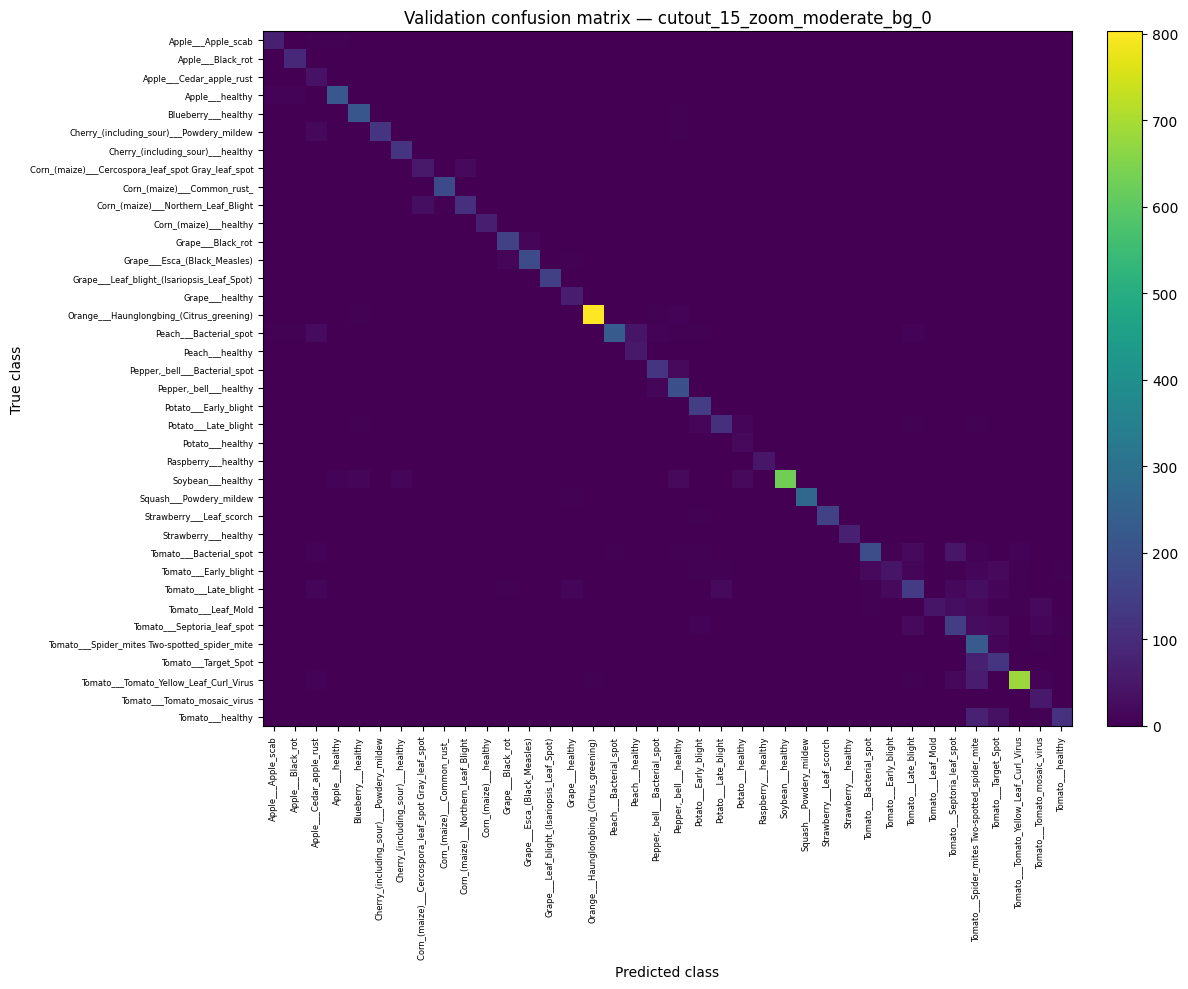

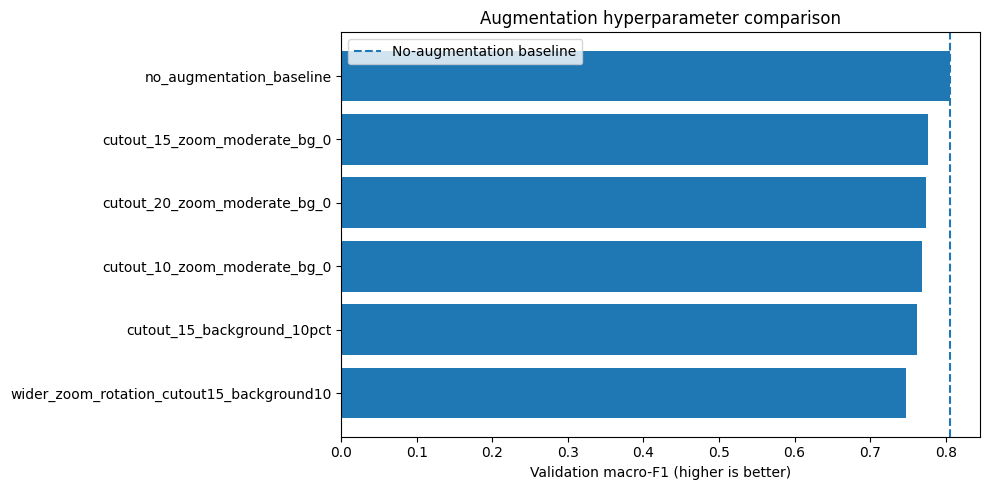

Saved: /kaggle/working/augmentation_handoff_pytorch/augmentation_tuning_results.csv
Saved: /kaggle/working/augmentation_handoff_pytorch/best_augmented_per_class_f1.csv
Saved: /kaggle/working/augmentation_handoff_pytorch/best_augmented_confusion_matrix.csv
Saved: /kaggle/working/augmentation_handoff_pytorch/best_augmented_confusion_matrix.png
Saved: /kaggle/working/augmentation_handoff_pytorch/augmentation_tuning_macro_f1.png


,class,validation_f1
29,Tomato___Early_blight,0.410480
31,Tomato___Leaf_Mold,0.465608
22,Potato___healthy,0.481928
2,Apple___Cedar_apple_rust,0.512821
32,Tomato___Septoria_leaf_spot,0.540441
34,Tomato___Target_Spot,0.548753
30,Tomato___Late_blight,0.556660
33,Tomato___Spider_mites Two-spotted_spider_mite,0.567534
37,Tomato___healthy,0.614555
36,Tomato___Tomato_mosaic_virus,0.643678


In [20]:
results_path = OUTPUT_DIR / "augmentation_tuning_results.csv"
results_df.sort_values(["val_macro_f1", "val_accuracy"], ascending=False).to_csv(results_path, index=False)

baseline_row = results_df.loc[results_df["config_name"] == "no_augmentation_baseline"].iloc[0]
augmented_results = results_df[results_df["augmentation"]].copy()
best_augmented_row = augmented_results.sort_values(
    ["val_macro_f1", "val_accuracy"], ascending=False
).iloc[0]
best_augmented_name = best_augmented_row["config_name"]
best_augmented_config = next(c for c in TUNING_CONFIGS if c["name"] == best_augmented_name)
baseline_macro_f1 = float(baseline_row["val_macro_f1"])
best_augmented_macro_f1 = float(best_augmented_row["val_macro_f1"])
beats_baseline = best_augmented_macro_f1 >= baseline_macro_f1

selected_config_payload = {
    "selected_config_name": best_augmented_name,
    "best_overall_validation_config": str(results_df.sort_values(["val_macro_f1", "val_accuracy"], ascending=False).iloc[0]["config_name"]),
    "best_overall_is_augmented": bool(results_df.sort_values(["val_macro_f1", "val_accuracy"], ascending=False).iloc[0]["augmentation"]),
    "best_overall_validation_macro_f1": float(results_df.sort_values(["val_macro_f1", "val_accuracy"], ascending=False).iloc[0]["val_macro_f1"]),
    "selection_metric": "validation_macro_f1",
    "selected_validation_macro_f1": best_augmented_macro_f1,
    "selected_validation_accuracy": float(best_augmented_row["val_accuracy"]),
    "best_epoch": int(best_augmented_row["best_epoch"]),
    "baseline_validation_macro_f1": baseline_macro_f1,
    "baseline_validation_accuracy": float(baseline_row["val_accuracy"]),
    "macro_f1_delta_vs_baseline": best_augmented_macro_f1 - baseline_macro_f1,
    "beats_or_matches_no_augmentation_baseline": bool(beats_baseline),
    "recommend_using_augmentation_over_baseline": bool(beats_baseline),
    "training_subset_images": int(len(tune_train_df)),
    "validation_images": int(len(tune_val_df)),
    "test_set_used": False,
    "background_masks_visually_approved": BACKGROUND_MASKS_APPROVED,
    "transform_kwargs": best_augmented_config["transform_kwargs"],
}
config_path = OUTPUT_DIR / "best_augmented_config.json"
config_path.write_text(json.dumps(selected_config_payload, indent=2), encoding="utf-8")

# Also save a concise human-readable note stating whether augmentation beat the baseline.
if beats_baseline:
    recommendation = "The best tested augmentation matched or beat the no-augmentation baseline on validation macro-F1."
else:
    recommendation = "The best tested augmentation did NOT beat the no-augmentation baseline on validation macro-F1; discuss with the model owner before adopting it."
print("Recommended augmented candidate:", best_augmented_name)
print(f"Best augmented validation macro-F1: {best_augmented_macro_f1:.4f}")
print(f"No-augmentation baseline macro-F1: {baseline_macro_f1:.4f}")
print(f"Delta vs baseline: {best_augmented_macro_f1 - baseline_macro_f1:+.4f}")
print(recommendation)
print("Saved selected parameters to:", config_path)

# Save per-class F1 and a confusion matrix for the selected augmented candidate.
selected_predictions = TUNING_ARTIFACTS[best_augmented_name]["predictions"]
selected_per_class_f1 = f1_score(
    val_labels.numpy(), selected_predictions,
    labels=list(range(len(class_names))), average=None, zero_division=0,
)
per_class_df = pd.DataFrame({"class": class_names, "validation_f1": selected_per_class_f1})
per_class_path = OUTPUT_DIR / "best_augmented_per_class_f1.csv"
per_class_df.to_csv(per_class_path, index=False)

cm = confusion_matrix(
    val_labels.numpy(), selected_predictions, labels=list(range(len(class_names)))
)
cm_df = pd.DataFrame(cm, index=class_names, columns=class_names)
cm_path = OUTPUT_DIR / "best_augmented_confusion_matrix.csv"
cm_df.to_csv(cm_path)

fig, ax = plt.subplots(figsize=(12, 10))
image = ax.imshow(cm, interpolation="nearest", aspect="auto")
ax.set_title(f"Validation confusion matrix — {best_augmented_name}")
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
ax.set_xticks(range(len(class_names)))
ax.set_yticks(range(len(class_names)))
ax.set_xticklabels(class_names, rotation=90, fontsize=6)
ax.set_yticklabels(class_names, fontsize=6)
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
fig.tight_layout()
cm_png_path = OUTPUT_DIR / "best_augmented_confusion_matrix.png"
fig.savefig(cm_png_path, dpi=180, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
plot_results = results_df.sort_values("val_macro_f1", ascending=True)
ax.barh(plot_results["config_name"], plot_results["val_macro_f1"])
ax.axvline(baseline_macro_f1, linestyle="--", label="No-augmentation baseline")
ax.set_xlabel("Validation macro-F1 (higher is better)")
ax.set_title("Augmentation hyperparameter comparison")
ax.legend()
fig.tight_layout()
scores_plot_path = OUTPUT_DIR / "augmentation_tuning_macro_f1.png"
fig.savefig(scores_plot_path, dpi=180, bbox_inches="tight")
plt.show()

print("Saved:", results_path)
print("Saved:", per_class_path)
print("Saved:", cm_path)
print("Saved:", cm_png_path)
print("Saved:", scores_plot_path)
display(per_class_df.sort_values("validation_f1").head(10))

## Next steps

The selected configuration is in `best_augmented_config.json`, and the reusable implementation is in `augmentation_pipeline.py`. Keep the train/validation/test split unchanged. Apply augmentation only to `train`; use deterministic evaluation transforms for `val` and `test`.

```python
import json
from augmentation_pipeline import load_rgb_image, build_train_transform, build_eval_transform

with open("best_augmented_config.json", "r", encoding="utf-8") as file:
    selected = json.load(file)

train_transform = build_train_transform(**selected["transform_kwargs"], normalize=True)
eval_transform = build_eval_transform(normalize=True)

image = load_rgb_image(row["resolved_image_path"])
if row["split"] == "train":
    image_tensor = train_transform(image)
else:
    image_tensor = eval_transform(image)
```
